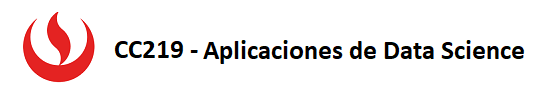

<h3 align="center"><b>PC4-Practica 4:</b> Sistema de Recomendación Hibridos</h3>
<h3 align="left"><b>Profesor:</b> Mg. Gustavo Adolfo López Abarca</h3>
<h3 align="left"><b>Duración:</b>  2 horas</h3>
<h3 align="center">2026-2</h3>




---


**Nombre del Alumno:**  
**Código:**  


---



### **Caso de Estudio: Sistema de Recomendación Hibridos**




**Empresa: Plataforma Streaming**

Objetivo: Una plataforma de streaming necesita recomendar películas relevantes y, al mismo tiempo, favorecer el descubrimiento de contenido de su catálogo.

**Dataset**: MovieLens 1M (fuente oficial GroupLens; copia de referencia en Kaggle). La descarga automática utiliza GroupLens y no requiere una cuenta de Kaggle. Se utilizan ratings.dat y movies.dat.

**Contexto del Examen:**

* Resuelve exclusivamente las seis preguntas. Debajo de cada enunciado agrega las celdas de código y los comentarios que necesites.
* Utiliza solo train para construir modelos, val para seleccionar parámetros y test para la evaluación final. No utilices test para entrenar ni ajustar modelos.

* Rating ≥ 4 se considera relevante; evalúa Top-5 y Top-10, excluyendo películas conocidas en train.

* Entrega un notebook ejecutable de principio a fin, con resultados obtenidos mediante código. La defensa se realizará utilizando ese mismo notebook.


  **PREGUNTA 1: Recomendadores por popularidad y texto TF-IDF**

  * Implementa dos modelos base independientes: uno que recomiende películas según su popularidad y otro que utilice TF-IDF aplicado al texto de los títulos de las películas para generar recomendaciones personalizadas a partir del historial del usuario.
  
   * Presenta el Top-5 y Top-10 de ambos modelos para dos usuarios, identifica diferencias en sus recomendaciones y sustenta cuál de ellos responde mejor a las preferencias individuales.
   

  **PREGUNTA 2: Filtrado colaborativo y contenido por géneros**
    
  * Implementa dos modelos base adicionales: uno de filtrado colaborativo con similitud coseno y otro basado en contenido mediante géneros cinematográficos. Genera recomendaciones personalizadas Top-5 y Top-10, excluyendo películas vistas en entrenamiento.

  * Compara ambos enfoques para dos usuarios e interpreta las diferencias de sus recomendaciones.


  **PREGUNTA 3: Construye dos recomendadores híbridos**


  * Implementa dos estrategias híbridas de integración diferentes que combinen los modelos base desarrollados en las preguntas 1 y 2. Al menos una debe adaptarse a características observables del historial del usuario.

  * Selecciona sus parámetros utilizando train y val, justifica las decisiones de integración y muestra un caso concreto donde los dos híbridos produzcan rankings diferentes, explicando el motivo.
  
  
  **PREGUNTA 4: Evalúa y cuestiona el ranking**
  
   * Evalúa los seis modelos (popularidad, texto TF-IDF, filtrado colaborativo por coseno, contenido por géneros y los dos híbridos) en test usando Precision@K, Recall@K, NDCG@K, cobertura del catálogo, diversidad intralista y novedad, para K = 5 y K = 10.
   
   * Presenta una comparación consolidada, verifica tus métricas con pruebas automáticas sobre ejemplos pequeños y demuestra con resultados un caso en el que una mayor relevancia tenga un costo en otra dimensión.

  **PREGUNTA 5: Investiga la robustez del mejor híbrido**
  
   * Selecciona uno de tus híbridos con base en los resultados de validación y realiza dos experimentos de sensibilidad: uno con menos historial de usuario y otro con una restricción a la concentración de películas populares.
   
   * Compara los resultados con la configuración original utilizando las seis métricas, presenta diferencias entre grupos de usuarios y concluye qué compromisos revela cada experimento.



   **PREGUNTA 6: Decide y defiende una solución de negocio**

   * Para una plataforma que busca aumentar el descubrimiento de películas poco populares sin sacrificar excesivamente la relevancia, recomienda un único modelo para un piloto.
   
   * Sustenta tu elección con una matriz de decisión ponderada, dos riesgos técnicos, una limitación de los datos y una condición observable que te haría reconsiderar la elección.
   
   * Prepara una defensa, ejecutando tu notebook para mostrar una recomendación concreta, una prueba automática y un resultado experimental inesperado.









    

## **Cargamos el Dataset:**

* Cargamos la información


In [1]:
# Se descargan únicamente los dos archivos necesarios para el laboratorio.
%pip -q install pandas numpy scipy scikit-learn

from pathlib import Path
from urllib.request import urlopen, Request
from zipfile import ZipFile
from io import BytesIO

DATA_DIR = Path("ml-1m")
DATA_DIR.mkdir(parents=True, exist_ok=True)
URL_MOVIELENS = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
ARCHIVOS = ("ratings.dat", "movies.dat")

if all((DATA_DIR / nombre).is_file() for nombre in ARCHIVOS):
    print("Dataset listo: se encontraron los archivos locales en", DATA_DIR.resolve())
else:
    try:
        print("Descargando MovieLens 1M desde GroupLens (fuente oficial)...")
        peticion = Request(URL_MOVIELENS, headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(peticion, timeout=60) as respuesta:
            contenido = respuesta.read()
        with ZipFile(BytesIO(contenido)) as zip_file:
            for nombre in ARCHIVOS:
                ruta_zip = f"ml-1m/{nombre}"
                with zip_file.open(ruta_zip) as origen, (DATA_DIR / nombre).open("wb") as destino:
                    import shutil
                    shutil.copyfileobj(origen, destino)
        print("Descarga y extracción completadas.")
    except Exception as exc:
        print("La descarga automática no estuvo disponible:", str(exc)[:160])
        print("Alternativa: descarga el ZIP oficial desde:", URL_MOVIELENS)
        print("Descomprímelo y deja ratings.dat y movies.dat en ./ml-1m/")

faltantes = [nombre for nombre in ARCHIVOS if not (DATA_DIR / nombre).is_file()]
if faltantes:
    raise FileNotFoundError(
        f"Faltan {faltantes}. Descarga el ZIP desde {URL_MOVIELENS} "
        "y coloca ratings.dat y movies.dat en ./ml-1m/. "
        "Vuelve a ejecutar esta celda."
    )

for nombre in ARCHIVOS:
    print(f"OK: {(DATA_DIR / nombre).resolve()}")


## **Ahora desarrolla tu solución**

**PREGUNTA 1: Recomendadores por popularidad y texto TF-IDF**


  * Implementa dos modelos base independientes: uno que recomiende películas según su popularidad y otro que utilice TF-IDF aplicado al texto de los títulos de las películas para generar recomendaciones personalizadas a partir del historial del usuario.

  * Presenta el Top-5 y Top-10 de ambos modelos para dos usuarios, identifica diferencias en sus recomendaciones y sustenta cuál de ellos responde mejor a las preferencias individuales.

In [2]:
# 1. Cargar las bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

In [3]:
# 2. Cargar los datos
ratings = pd.read_csv(DATA_DIR / "ratings.dat", sep="::", engine="python", encoding="latin-1",
                      names=["userId", "movieId", "rating", "timestamp"])
movies = pd.read_csv(DATA_DIR / "movies.dat", sep="::", engine="python", encoding="latin-1",
                     names=["movieId", "title", "genres"])
print("Ratings:", ratings.shape, "| Películas:", movies.shape)
print("Usuarios:", ratings["userId"].nunique(), "| Películas con rating:", ratings["movieId"].nunique())
display(ratings.head())
display(movies.head())

Ratings: (1000209, 4) | Películas: (3883, 3)
Usuarios: 6040 | Películas con rating: 3706


,userId,movieId,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


,movieId,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
# 3. Dividir en train, val y test
train, temp = train_test_split(ratings, test_size=0.30, random_state=42, stratify=ratings["userId"])
val, test = train_test_split(temp, test_size=0.50, random_state=42, stratify=temp["userId"])
print("train:", train.shape, "| val:", val.shape, "| test:", test.shape)

vistas_train = train.groupby("userId")["movieId"].apply(set).to_dict()
gustos_train = {u: g.set_index("movieId")["rating"]
                for u, g in train[train["rating"] >= 4].groupby("userId")}

train: (700146, 4) | val: (150031, 4) | test: (150032, 4)


In [5]:
# 4. Modelo 1: popularidad
popularidad = (train[train["rating"] >= 4].groupby("movieId").size()
               .reindex(movies["movieId"], fill_value=0)
               .sort_values(ascending=False, kind="stable"))

def recomendar_popularidad(userId, k=10):
    vistas = vistas_train.get(userId, set())
    candidatos = popularidad[~popularidad.index.isin(vistas)]
    return candidatos.head(k).index.tolist()

In [6]:
# 5. Modelo 2: TF-IDF sobre títulos
movies["texto"] = movies["title"].str.replace(r"\(\d{4}\)", "", regex=True).str.strip()
vectorizador = TfidfVectorizer(lowercase=True, strip_accents="unicode",
                               ngram_range=(1, 2), stop_words="english")
X_texto = vectorizador.fit_transform(movies["texto"])
sim_texto = pd.DataFrame(cosine_similarity(X_texto),
                         index=movies["movieId"], columns=movies["movieId"])

def recomendar_texto(userId, k=10):
    if userId not in gustos_train:
        return recomendar_popularidad(userId, k)
    gustadas = gustos_train[userId]
    scores = sim_texto[gustadas.index].dot(gustadas.values) / gustadas.sum()
    scores.loc[list(vistas_train[userId])] = -np.inf
    return scores.sort_values(ascending=False).head(k).index.tolist()

In [7]:
# 6. Top-5 y Top-10 para dos usuarios
titulos = movies.set_index("movieId")["title"]
usuarios_demo = [1, 2]
for u in usuarios_demo:
    print(f"\n===== Usuario {u} | vistas en train: {len(vistas_train[u])} =====")
    print("Algunas películas que le gustaron (rating >= 4):")
    display(titulos.loc[gustos_train[u].sort_values(ascending=False).head(8).index].to_frame("title"))
    for k in [5, 10]:
        tabla = pd.DataFrame({
            "Popularidad": titulos.loc[recomendar_popularidad(u, k)].values,
            "TF-IDF títulos": titulos.loc[recomendar_texto(u, k)].values
        }, index=range(1, k + 1))
        print(f"Top-{k}")
        display(tabla)


===== Usuario 1 | vistas en train: 37 =====
Algunas películas que le gustaron (rating >= 4):


,title
movieId,
1270,Back to the Future (1985)
1287,Ben-Hur (1959)
2355,"Bug's Life, A (1998)"
3105,Awakenings (1990)
1193,One Flew Over the Cuckoo's Nest (1975)
595,Beauty and the Beast (1991)
1022,Cinderella (1950)
1961,Rain Man (1988)


Top-5


,Popularidad,TF-IDF títulos
1,American Beauty (1999),Ever After: A Cinderella Story (1998)
2,Star Wars: Episode IV - A New Hope (1977),Miracle on 34th Street (1994)
3,Star Wars: Episode V - The Empire Strikes Back...,"Big One, The (1997)"
4,Saving Private Ryan (1998),Back to the Future Part II (1989)
5,Raiders of the Lost Ark (1981),Rain (1932)


Top-10


,Popularidad,TF-IDF títulos
1,American Beauty (1999),Ever After: A Cinderella Story (1998)
2,Star Wars: Episode IV - A New Hope (1977),Miracle on 34th Street (1994)
3,Star Wars: Episode V - The Empire Strikes Back...,"Big One, The (1997)"
4,Saving Private Ryan (1998),Back to the Future Part II (1989)
5,Raiders of the Lost Ark (1981),Rain (1932)
6,"Silence of the Lambs, The (1991)",Back to the Future Part III (1990)
7,"Matrix, The (1999)",Beauty (1998)
8,Star Wars: Episode VI - Return of the Jedi (1983),"Last Days, The (1998)"
9,"Shawshank Redemption, The (1994)","Story of Us, The (1999)"
10,Fargo (1996),L.A. Story (1991)


... (2 outputs left out)

Top-5


,Popularidad,TF-IDF títulos
1,Star Wars: Episode IV - A New Hope (1977),Die Hard (1988)
2,Star Wars: Episode VI - Return of the Jedi (1983),Rocky V (1990)
3,"Sixth Sense, The (1999)",Mission: Impossible 2 (2000)
4,"Shawshank Redemption, The (1994)","Misérables, Les (1995)"
5,Schindler's List (1993),Rocky II (1979)


Top-10


,Popularidad,TF-IDF títulos
1,Star Wars: Episode IV - A New Hope (1977),Die Hard (1988)
2,Star Wars: Episode VI - Return of the Jedi (1983),Rocky V (1990)
3,"Sixth Sense, The (1999)",Mission: Impossible 2 (2000)
4,"Shawshank Redemption, The (1994)","Misérables, Les (1995)"
5,Schindler's List (1993),Rocky II (1979)
6,Fargo (1996),Rocky III (1982)
7,Terminator 2: Judgment Day (1991),"Good Earth, The (1937)"
8,"Godfather, The (1972)","Good Mother, The (1988)"
9,Back to the Future (1985),Beyond Silence (1996)
10,"Princess Bride, The (1987)",Rocky IV (1985)


In [8]:
# 7. Diferencias entre usuarios
u1, u2 = usuarios_demo
for k in [5, 10]:
    comun_pop = len(set(recomendar_popularidad(u1, k)) & set(recomendar_popularidad(u2, k)))
    comun_txt = len(set(recomendar_texto(u1, k)) & set(recomendar_texto(u2, k)))
    print(f"Top-{k} | en común entre usuarios -> Popularidad: {comun_pop}/{k} | TF-IDF: {comun_txt}/{k}")

Top-5 | en común entre usuarios -> Popularidad: 1/5 | TF-IDF: 0/5
Top-10 | en común entre usuarios -> Popularidad: 4/10 | TF-IDF: 0/10


**Respuesta Pregunta 1**

Decisiones: split 70/15/15 aleatorio estratificado por usuario; popularidad = cantidad de ratings ≥ 4 en train; al título se le quita el año y las stopwords en inglés.

**Diferencias.** Popularidad entrega el mismo ranking global y solo cambia por las películas que cada usuario ya vio: los usuarios 1 y 2 comparten 1 de 5 y 4 de 10 recomendaciones. Con TF-IDF no comparten ninguna (0 de 5 y 0 de 10): al usuario 1 le salen las secuelas de *Back to the Future* y *Ever After: A Cinderella Story*; al usuario 2, *Die Hard* (vio *Die Hard 2*) y la saga *Rocky*.

**Cuál responde mejor a las preferencias individuales.** TF-IDF, porque sus listas dependen de lo que le gustó a cada usuario. Sin embargo comete errores por coincidencia de palabras: *Rain (1932)* aparece por *Rain Man* y *Beauty (1998)* por *Beauty and the Beast*. Que personalice más no significa que acierte más; eso se mide en la Pregunta 4.

**Interpretación empresarial**
- Entrada => el usuario y su historial de ratings en train.
- Datos => cantidad de ratings ≥ 4 por película (popularidad) y texto de los títulos (TF-IDF).
- Modelo => ranking global por popularidad, y similitud del coseno entre los títulos que le gustaron al usuario y el resto del catálogo.
- Salida => Top-5 y Top-10 de películas no vistas en train.
- Beneficio esperado => popularidad es una base segura para usuarios nuevos; TF-IDF encuentra secuelas y sagas y muestra títulos menos masivos.

**Limitación:** el título tiene muy poco texto, así que TF-IDF solo detecta palabras repetidas, no significado ni género. Popularidad concentra las recomendaciones en los mismos éxitos.

**PREGUNTA 2: Filtrado colaborativo y contenido por géneros**

* Implementa dos modelos base adicionales: uno de filtrado colaborativo con similitud coseno y otro basado en contenido mediante géneros cinematográficos. Genera recomendaciones personalizadas Top-5 y Top-10, excluyendo películas vistas en entrenamiento.

* Compara ambos enfoques para dos usuarios e interpreta las diferencias de sus recomendaciones.

In [9]:
# 8. Modelo 3: filtrado colaborativo ítem-ítem con similitud coseno
matriz = train.pivot_table(index="userId", columns="movieId", values="rating")
matriz_items = matriz.T.reindex(movies["movieId"]).fillna(0)     # mismas películas que el catálogo
sim_cf = pd.DataFrame(cosine_similarity(matriz_items),
                      index=matriz_items.index, columns=matriz_items.index)
print("Matriz usuario-película:", matriz.shape, "| Similitud CF:", sim_cf.shape)

def puntajes_historial(userId, similitud):
    # promedio ponderado de similitud con las películas que le gustaron
    gustadas = gustos_train[userId]
    scores = similitud[gustadas.index].dot(gustadas.values) / gustadas.sum()
    scores.loc[list(vistas_train[userId])] = -np.inf             # excluir vistas
    return scores

def recomendar_colaborativo(userId, k=10):
    if userId not in gustos_train:
        return recomendar_popularidad(userId, k)
    scores = puntajes_historial(userId, sim_cf)
    return scores.sort_values(ascending=False, kind="stable").head(k).index.tolist()

Matriz usuario-película: (6040, 3661) | Similitud CF: (3883, 3883)


In [10]:
# 9. Modelo 4: contenido por géneros
tfidf = TfidfVectorizer(tokenizer=lambda x: x.split("|"), token_pattern=None)
matriz_tfidf = tfidf.fit_transform(movies["genres"].fillna(""))
posicion = pd.Series(range(len(movies)), index=movies["movieId"])   # fila de cada película
print("Géneros:", len(tfidf.get_feature_names_out()))

def puntajes_generos(userId):
    # perfil del usuario = suma ponderada de los géneros de las películas que le gustaron
    gustadas = gustos_train[userId]
    perfil = gustadas.values @ matriz_tfidf[posicion[gustadas.index].values].toarray()
    scores = pd.Series(cosine_similarity(perfil.reshape(1, -1), matriz_tfidf).ravel(),
                       index=movies["movieId"])
    scores.loc[list(vistas_train[userId])] = -np.inf             # excluir vistas
    return scores

def recomendar_generos(userId, k=10):
    if userId not in gustos_train:
        return recomendar_popularidad(userId, k)
    scores = puntajes_generos(userId).round(6)
    # muchas películas empatan (mismos géneros): desempate aleatorio con semilla fija por usuario
    desempate = np.random.RandomState(userId).rand(len(scores))
    orden = pd.DataFrame({"score": scores, "desempate": desempate}, index=scores.index)
    return orden.sort_values(["score", "desempate"], ascending=False).head(k).index.tolist()

Géneros: 18


In [11]:
# 10. Top-5 y Top-10 de ambos modelos para dos usuarios
generos = movies.set_index("movieId")["genres"]

for u in usuarios_demo:
    print(f"\n===== Usuario {u} | vistas en train: {len(vistas_train[u])} =====")
    print("Géneros más frecuentes entre las películas que le gustaron:")
    display(generos.loc[gustos_train[u].index].str.split("|").explode().value_counts().head(5).to_frame("películas"))
    for k in [5, 10]:
        rec_cf, rec_gen = recomendar_colaborativo(u, k), recomendar_generos(u, k)
        tabla = pd.DataFrame({
            "Colaborativo": titulos.loc[rec_cf].values,
            "Géneros CF": generos.loc[rec_cf].values,
            "Contenido (géneros)": titulos.loc[rec_gen].values,
            "Géneros CB": generos.loc[rec_gen].values
        }, index=range(1, k + 1))
        print(f"Top-{k}")
        display(tabla)


===== Usuario 1 | vistas en train: 37 =====
Géneros más frecuentes entre las películas que le gustaron:


,películas
genres,
Drama,15
Children's,12
Animation,11
Musical,9
Comedy,7


Top-5


,Colaborativo,Géneros CF,Contenido (géneros),Géneros CB
1,E.T. the Extra-Terrestrial (1982),Children's|Drama|Fantasy|Sci-Fi,"Wood, The (1999)",Drama
2,Toy Story (1995),Animation|Children's|Comedy,"Killing of Sister George, The (1968)",Drama
3,"Lion King, The (1994)",Animation|Children's|Musical,Ruby in Paradise (1993),Drama
4,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,"Last Time I Saw Paris, The (1954)",Drama
5,Raiders of the Lost Ark (1981),Action|Adventure,Amadeus (1984),Drama


Top-10


,Colaborativo,Géneros CF,Contenido (géneros),Géneros CB
1,E.T. the Extra-Terrestrial (1982),Children's|Drama|Fantasy|Sci-Fi,"Wood, The (1999)",Drama
2,Toy Story (1995),Animation|Children's|Comedy,"Killing of Sister George, The (1968)",Drama
3,"Lion King, The (1994)",Animation|Children's|Musical,Ruby in Paradise (1993),Drama
4,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,"Last Time I Saw Paris, The (1954)",Drama
5,Raiders of the Lost Ark (1981),Action|Adventure,Amadeus (1984),Drama
6,Groundhog Day (1993),Comedy|Romance,S.F.W. (1994),Drama
7,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi,Tess of the Storm Country (1922),Drama
8,"Shawshank Redemption, The (1994)",Drama,"Legend of 1900, The (Leggenda del pianista sul...",Drama
9,"Silence of the Lambs, The (1991)",Drama|Thriller,August (1996),Drama
10,Fantasia (1940),Animation|Children's|Musical,Snow Falling on Cedars (1999),Drama


... (2 outputs left out)

Top-5


,Colaborativo,Géneros CF,Contenido (géneros),Géneros CB
1,"Shawshank Redemption, The (1994)",Drama,King of the Hill (1993),Drama
2,Fargo (1996),Crime|Drama|Thriller,Defying Gravity (1997),Drama
3,E.T. the Extra-Terrestrial (1982),Children's|Drama|Fantasy|Sci-Fi,"Bamba, La (1987)",Drama
4,Pulp Fiction (1994),Crime|Drama,Time Regained (Le Temps Retrouvé) (1999),Drama
5,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi,Nobody's Fool (1994),Drama


Top-10


,Colaborativo,Géneros CF,Contenido (géneros),Géneros CB
1,"Shawshank Redemption, The (1994)",Drama,King of the Hill (1993),Drama
2,Fargo (1996),Crime|Drama|Thriller,Defying Gravity (1997),Drama
3,E.T. the Extra-Terrestrial (1982),Children's|Drama|Fantasy|Sci-Fi,"Bamba, La (1987)",Drama
4,Pulp Fiction (1994),Crime|Drama,Time Regained (Le Temps Retrouvé) (1999),Drama
5,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi,Nobody's Fool (1994),Drama
6,Back to the Future (1985),Comedy|Sci-Fi,Two or Three Things I Know About Her (1966),Drama
7,Schindler's List (1993),Drama|War,Under Capricorn (1949),Drama
8,"Godfather, The (1972)",Action|Crime|Drama,"They Shoot Horses, Don't They? (1969)",Drama
9,Die Hard (1988),Action|Thriller,He Got Game (1998),Drama
10,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,"Chamber, The (1996)",Drama


In [12]:
# 11. Comparación de los dos enfoques
filas = []
for u in usuarios_demo:
    for k in [5, 10]:
        rec_cf, rec_gen = recomendar_colaborativo(u, k), recomendar_generos(u, k)
        filas.append({"usuario": u, "k": k,
                      "en_comun_CF_vs_generos": len(set(rec_cf) & set(rec_gen)),
                      "popularidad_media_CF": popularidad.loc[rec_cf].mean(),
                      "popularidad_media_generos": popularidad.loc[rec_gen].mean()})
display(pd.DataFrame(filas).round(1))

# Empates del modelo de géneros: películas con el mismo puntaje máximo
for u in usuarios_demo:
    s = puntajes_generos(u).round(6)
    print(f"Usuario {u}: {(s == s.max()).sum()} películas empatan en el primer lugar por géneros "
          f"(géneros: {generos.loc[s.idxmax()]})")

for k in [5, 10]:
    comun_cf = len(set(recomendar_colaborativo(u1, k)) & set(recomendar_colaborativo(u2, k)))
    comun_gen = len(set(recomendar_generos(u1, k)) & set(recomendar_generos(u2, k)))
    print(f"Top-{k} | en común entre usuarios -> Colaborativo: {comun_cf}/{k} | Géneros: {comun_gen}/{k}")

,usuario,k,en_comun_CF_vs_generos,popularidad_media_CF,popularidad_media_generos
0,1,5,0,1236.2,175.6
1,1,10,0,1266.4,101.8
2,2,5,0,1439.0,41.8
3,2,10,0,1385.1,33.9


Usuario 1: 832 películas empatan en el primer lugar por géneros (géneros: Drama)
Usuario 2: 823 películas empatan en el primer lugar por géneros (géneros: Drama)
Top-5 | en común entre usuarios -> Colaborativo: 1/5 | Géneros: 0/5
Top-10 | en común entre usuarios -> Colaborativo: 3/10 | Géneros: 0/10


**Respuesta Pregunta 2**

Decisiones: colaborativo ítem-ítem con similitud coseno sobre la matriz usuario-película de train; contenido con un perfil de géneros por usuario (suma ponderada de los géneros de las películas que le gustaron) comparado por coseno con cada película. En géneros, más de 800 películas empatan en el primer lugar (832 para el usuario 1 y 823 para el usuario 2, todas de género "Drama"), por lo que se usa un desempate aleatorio con semilla fija por usuario.

**Diferencias.**
- Los dos enfoques no coinciden en ninguna película (0 en común en Top-5 y Top-10, para ambos usuarios).
- El colaborativo capta el gusto real y cruza géneros: al usuario 1 (infantil y animación) le da *Toy Story*, *Lion King* y *Fantasia*; al usuario 2 (drama y acción) le da *Shawshank*, *Pulp Fiction*, *Godfather* y *Die Hard*. Pero se inclina a lo popular: sus recomendaciones tienen en promedio entre 1,236 y 1,439 ratings positivos en train, y los dos usuarios comparten 3 de 10.
- Géneros recomienda películas poco conocidas (popularidad media entre 33.9 y 175.6), pero simplifica el perfil: al usuario 1 le gustan Children's, Animation y Musical casi tanto como Drama y aun así solo recibe dramas, porque una película de un solo género calza mejor con el perfil que una de tres géneros. Como hay cientos de empates, los títulos concretos los decide el desempate y no el gusto del usuario.

**Interpretación empresarial**
- Entrada => el usuario y las películas que calificó con 4 o más en train.
- Datos => matriz usuario-película de ratings (colaborativo) y géneros de cada película (contenido).
- Modelo => similitud coseno ítem-ítem sobre los ratings, y similitud coseno entre el perfil de géneros del usuario y cada película.
- Salida => Top-5 y Top-10 de películas no vistas en train.
- Beneficio esperado => el colaborativo ofrece recomendaciones creíbles y personalizadas; géneros expone catálogo poco visto y funciona con películas sin ratings.

**Limitación:** el colaborativo no puede recomendar películas sin ratings en train y refuerza las ya populares. Géneros tiene solo 18 categorías y no separa una buena película de una mala del mismo género.

**PREGUNTA 3: Construye dos recomendadores híbridos**

  * Implementa dos estrategias híbridas de integración diferentes que combinen los modelos base desarrollados en las preguntas 1 y 2. Al menos una debe adaptarse a características observables del historial del usuario.

  * Selecciona sus parámetros utilizando train y val, justifica las decisiones de integración y muestra un caso concreto donde los dos híbridos produzcan rankings diferentes, explicando el motivo.


In [13]:
# 12. Puntajes normalizados de los cuatro modelos base para un usuario
MODELOS = ["Popularidad", "CF", "Generos", "Texto"]
pop_base = popularidad.reindex(movies["movieId"]).values.astype(float)
S_cf, S_txt = sim_cf.values, sim_texto.values
ids = movies["movieId"].values

def componentes(userId):
    # matriz (películas x 4) con min-max entre candidatos, y máscara de candidatos (no vistas)
    comp = np.zeros((len(movies), 4))
    comp[:, 0] = pop_base
    if userId in gustos_train:
        g = gustos_train[userId]
        idx, w = posicion[g.index].values, g.values
        comp[:, 1] = w @ S_cf[idx] / w.sum()
        comp[:, 2] = cosine_similarity((w @ matriz_tfidf[idx].toarray()).reshape(1, -1), matriz_tfidf).ravel()
        comp[:, 3] = w @ S_txt[idx] / w.sum()
    candidatos = np.ones(len(movies), dtype=bool)
    candidatos[posicion[list(vistas_train.get(userId, []))].values] = False
    comp[candidatos] = MinMaxScaler().fit_transform(comp[candidatos])
    return comp, candidatos

def ranking(comp, candidatos, pesos, k=10):
    scores = comp @ np.array(pesos)
    scores[~candidatos] = -np.inf                      # excluir vistas
    return ids[np.argsort(-scores, kind="stable")[:k]].tolist()

In [14]:
# 13. Métricas (Precision@K y NDCG@K) para seleccionar parámetros en val
def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / k

def ndcg_at_k(recommended, relevant, k):
    relevance = np.array([1 if item in relevant else 0 for item in recommended[:k]])
    discounts = np.log2(np.arange(2, len(relevance) + 2))
    dcg = np.sum(relevance / discounts)
    idcg = np.sum(np.sort(relevance)[::-1] / discounts)
    return dcg / idcg if idcg > 0 else 0

relevantes_val = val[val["rating"] >= 4].groupby("userId")["movieId"].apply(set).to_dict()

# muestra fija de usuarios de val (para que la búsqueda sea rápida)
usuarios_val = pd.Series(sorted(relevantes_val)).sample(1000, random_state=42).tolist()
cache_val = {u: componentes(u) for u in usuarios_val}

def evaluar_val(pesos, usuarios=usuarios_val, k=10):
    p, n = [], []
    for u in usuarios:
        rec = ranking(*cache_val[u], pesos, k)
        p.append(precision_at_k(rec, relevantes_val[u], k))
        n.append(ndcg_at_k(rec, relevantes_val[u], k))
    return np.mean(p), np.mean(n)

print("Modelos base en val (Precision@10, NDCG@10):")
for i, m in enumerate(MODELOS):
    print(m, np.round(evaluar_val(np.eye(4)[i]), 4))

Modelos base en val (Precision@10, NDCG@10):


Popularidad [0.1013 0.3292]


CF [0.1557 0.4585]
Generos [0.0185 0.076 ]


Texto [0.0305 0.1286]


In [15]:
# 14. Híbrido 1 (ponderado global): mismos pesos para todos, elegidos por NDCG@10 en val
pasos = np.round(np.arange(0.1, 0.71, 0.1), 1)          # cada modelo pesa al menos 0.1
grilla = [c for c in product(pasos, repeat=4) if abs(sum(c) - 1) < 1e-9]
print("\nCombinaciones de pesos probadas:", len(grilla))

ndcg_usuario = {}
for pesos in grilla:
    ndcg_usuario[pesos] = [ndcg_at_k(ranking(*cache_val[u], pesos, 10), relevantes_val[u], 10)
                           for u in usuarios_val]
tabla_ndcg = pd.DataFrame(ndcg_usuario, index=usuarios_val)   # filas: usuarios, columnas: pesos

pesos_h1 = tabla_ndcg.mean().idxmax()
print("Mejores 5 combinaciones en val (Popularidad, CF, Generos, Texto):")
display(tabla_ndcg.mean().sort_values(ascending=False).head(5).round(4).to_frame("NDCG@10 val"))
print("Pesos Híbrido 1:", dict(zip(MODELOS, map(float, pesos_h1))))


Combinaciones de pesos probadas: 84


Mejores 5 combinaciones en val (Popularidad, CF, Generos, Texto):


NDCG@10 val
0.1 0.7 0.1 0.1       0.4544
    0.6 0.2 0.1       0.4496
0.2 0.5 0.2 0.1       0.4380
0.1 0.6 0.1 0.2       0.4376
0.2 0.6 0.1 0.1       0.4343

Pesos Híbrido 1: {'Popularidad': 0.1, 'CF': 0.7, 'Generos': 0.1, 'Texto': 0.1}


In [16]:
# 15. Híbrido 2 (adaptativo): pesos distintos según el tamaño del historial del usuario
n_gustadas = pd.Series({u: len(g) for u, g in gustos_train.items()})
corte_bajo, corte_alto = n_gustadas.quantile([1/3, 2/3]).values   # terciles calculados en train
print("\nCortes de historial (películas con rating >= 4 en train):", corte_bajo, corte_alto)

def segmento_historial(userId):
    n = n_gustadas.get(userId, 0)
    return "bajo" if n <= corte_bajo else "medio" if n <= corte_alto else "alto"

segmentos_val = pd.Series({u: segmento_historial(u) for u in usuarios_val})
pesos_h2 = {}
for s in ["bajo", "medio", "alto"]:
    media = tabla_ndcg[segmentos_val == s].mean()
    pesos_h2[s] = media.idxmax()
    print(f"Segmento {s} ({(segmentos_val == s).sum()} usuarios): pesos {dict(zip(MODELOS, map(float, pesos_h2[s])))}"
          f" | NDCG@10 val = {media.max():.4f} (con pesos del Híbrido 1: {media[pesos_h1]:.4f})")


Cortes de historial (películas con rating >= 4 en train): 25.0 67.0
Segmento bajo (333 usuarios): pesos {'Popularidad': 0.1, 'CF': 0.6, 'Generos': 0.2, 'Texto': 0.1} | NDCG@10 val = 0.3073 (con pesos del Híbrido 1: 0.2966)
Segmento medio (346 usuarios): pesos {'Popularidad': 0.1, 'CF': 0.7, 'Generos': 0.1, 'Texto': 0.1} | NDCG@10 val = 0.4472 (con pesos del Híbrido 1: 0.4472)
Segmento alto (321 usuarios): pesos {'Popularidad': 0.1, 'CF': 0.7, 'Generos': 0.1, 'Texto': 0.1} | NDCG@10 val = 0.6257 (con pesos del Híbrido 1: 0.6257)


In [17]:
# 16. Funciones de recomendación de los dos híbridos y comparación en val
def recomendar_hibrido_ponderado(userId, k=10):
    return ranking(*componentes(userId), pesos_h1, k)

def recomendar_hibrido_adaptativo(userId, k=10):
    return ranking(*componentes(userId), pesos_h2[segmento_historial(userId)], k)

filas = {}
for i, m in enumerate(MODELOS):
    filas[m] = evaluar_val(np.eye(4)[i])
filas["Hibrido ponderado"] = evaluar_val(pesos_h1)
p, n = [], []
for u in usuarios_val:
    rec = ranking(*cache_val[u], pesos_h2[segmentos_val[u]], 10)
    p.append(precision_at_k(rec, relevantes_val[u], 10))
    n.append(ndcg_at_k(rec, relevantes_val[u], 10))
filas["Hibrido adaptativo"] = (np.mean(p), np.mean(n))
print("\nComparación en val:")
display(pd.DataFrame(filas, index=["Precision@10", "NDCG@10"]).T.round(4))


Comparación en val:


,Precision@10,NDCG@10
Popularidad,0.1013,0.3292
CF,0.1557,0.4585
Generos,0.0185,0.0760
Texto,0.0305,0.1286
Hibrido ponderado,0.1572,0.4544
Hibrido adaptativo,0.1574,0.4579


In [18]:
# 17. Caso concreto: un usuario donde los dos híbridos dan rankings distintos
print("Segmento de los usuarios demo:", {u: (segmento_historial(u), int(n_gustadas[u])) for u in usuarios_demo})
bajos = [u for u in usuarios_val if segmentos_val[u] == "bajo"]
u_caso = min(bajos, key=lambda u: len(set(recomendar_hibrido_ponderado(u)) & set(recomendar_hibrido_adaptativo(u))))
rec_h1, rec_h2 = recomendar_hibrido_ponderado(u_caso), recomendar_hibrido_adaptativo(u_caso)
print(f"\nUsuario {u_caso} | segmento: {segmento_historial(u_caso)} | gustadas en train: {n_gustadas[u_caso]}")
print("Géneros que más le gustaron:",
      generos.loc[gustos_train[u_caso].index].str.split("|").explode().value_counts().head(3).to_dict())
display(pd.DataFrame({"Hibrido ponderado": titulos.loc[rec_h1].values,
                      "Hibrido adaptativo": titulos.loc[rec_h2].values}, index=range(1, 11)))
print("En común en el Top-10:", len(set(rec_h1) & set(rec_h2)), "de 10")

# puntajes normalizados de las películas que solo aparecen en uno de los dos rankings
comp, cand = componentes(u_caso)
detalle = pd.DataFrame(comp, index=ids, columns=MODELOS)
solo = [m for m in rec_h1 if m not in rec_h2] + [m for m in rec_h2 if m not in rec_h1]
detalle = detalle.loc[solo].round(3)
detalle.insert(0, "title", titulos.loc[solo].values)
detalle["aparece_en"] = ["ponderado" if m in rec_h1 else "adaptativo" for m in solo]
detalle["score_H1"] = (comp[posicion[solo].values] @ np.array(pesos_h1)).round(3)
detalle["score_H2"] = (comp[posicion[solo].values] @ np.array(pesos_h2["bajo"])).round(3)
display(detalle)

Segmento de los usuarios demo: {1: ('medio', 32), 2: ('medio', 51)}



Usuario 4427 | segmento: bajo | gustadas en train: 10
Géneros que más le gustaron: {'Comedy': 6, "Children's": 3, 'Thriller': 3}


,Hibrido ponderado,Hibrido adaptativo
1,American Beauty (1999),American Beauty (1999)
2,"Silence of the Lambs, The (1991)",Ferris Bueller's Day Off (1986)
3,"Matrix, The (1999)","Silence of the Lambs, The (1991)"
4,Back to the Future (1985),Monty Python and the Holy Grail (1974)
5,Fargo (1996),As Good As It Gets (1997)
6,Forrest Gump (1994),Wayne's World (1992)
7,Ferris Bueller's Day Off (1986),"Christmas Story, A (1983)"
8,"Shawshank Redemption, The (1994)",Fargo (1996)
9,Terminator 2: Judgment Day (1991),"Breakfast Club, The (1985)"
10,"Sixth Sense, The (1999)",Being John Malkovich (1999)


En común en el Top-10: 4 de 10


,title,Popularidad,CF,Generos,Texto,aparece_en,score_H1,score_H2
2571,"Matrix, The (1999)",0.784,0.984,0.444,0.000,ponderado,0.812,0.758
1270,Back to the Future (1985),0.692,0.989,0.483,0.000,ponderado,0.810,0.759
356,Forrest Gump (1994),0.584,1.000,0.473,0.000,ponderado,0.806,0.753
318,"Shawshank Redemption, The (1994)",0.751,0.991,0.343,0.000,ponderado,0.803,0.738
589,Terminator 2: Judgment Day (1991),0.721,0.946,0.444,0.166,ponderado,0.795,0.745
2762,"Sixth Sense, The (1999)",0.760,0.952,0.492,0.000,ponderado,0.792,0.746
1136,Monty Python and the Holy Grail (1974),0.500,0.924,0.943,0.000,adaptativo,0.791,0.793
1784,As Good As It Gets (1997),0.371,0.932,0.937,0.000,adaptativo,0.784,0.784
3253,Wayne's World (1992),0.238,0.947,0.943,0.000,adaptativo,0.781,0.781
2804,"Christmas Story, A (1983)",0.401,0.831,0.937,0.465,adaptativo,0.762,0.772


**Respuesta Pregunta 3**

**Estrategias.** Los cuatro modelos base se normalizan con min-max entre las películas candidatas (no vistas) y se combinan con una suma ponderada.
- *Híbrido ponderado:* los mismos pesos para todos los usuarios.
- *Híbrido adaptativo:* los pesos dependen de una característica observable del historial: la cantidad de películas con rating ≥ 4 en train (segmentos bajo ≤ 25, medio 26 a 67, alto > 67; cortes por terciles de train).

**Selección de parámetros (train + val).** Se probaron 84 combinaciones de pesos (pasos de 0.1) y se eligió la de mayor NDCG@10 en una muestra fija de 1,000 usuarios de val. Se exige un peso mínimo de 0.1 por modelo para que el híbrido combine modelos de las preguntas 1 y 2; sin esa restricción val prefería 0.9 colaborativo + 0.1 géneros (NDCG@10 0.4672) con peso 0 para popularidad y texto.
- Híbrido ponderado: Popularidad 0.1, CF 0.7, Géneros 0.1, Texto 0.1 (NDCG@10 val 0.4544).
- Híbrido adaptativo: segmento bajo 0.1 / 0.6 / 0.2 / 0.1 (NDCG@10 sube de 0.2966 a 0.3073); medio y alto eligen los mismos pesos que el ponderado.

**Justificación.** El colaborativo es por mucho el mejor modelo base en val (NDCG@10 0.4585 frente a 0.3292 de popularidad, 0.1286 de texto y 0.0760 de géneros), por eso recibe el mayor peso. Con poco historial el colaborativo tiene menos señal y val prefiere darle más peso a los géneros.

**Caso con rankings diferentes: usuario 4427** (segmento bajo, 10 películas gustadas; géneros: Comedy 6, Children's 3, Thriller 3). Los dos Top-10 comparten solo 4 películas. El ponderado le da éxitos generales con puntaje de géneros bajo (*Matrix* 0.444, *Shawshank* 0.343). El adaptativo, al duplicar el peso de géneros, los reemplaza por comedias con puntaje de géneros entre 0.937 y 0.943 (*Monty Python and the Holy Grail*, *Wayne's World*, *Breakfast Club*).

**Advertencia.** La mejora del adaptativo es mínima (NDCG@10 val 0.4544 → 0.4579; Precision@10 0.1572 → 0.1574) y ninguno de los dos supera al colaborativo solo en NDCG@10 de val (0.4585). Los pesos por segmento se eligieron con los mismos usuarios de val, así que la mejora puede ser optimista.

**Interpretación empresarial**
- Entrada => el usuario, su historial en train y el tamaño de ese historial.
- Datos => los puntajes normalizados de popularidad, colaborativo, géneros y texto de títulos.
- Modelo => suma ponderada con pesos fijos (híbrido ponderado) o con pesos según el segmento de historial (híbrido adaptativo), elegidos por NDCG@10 en val.
- Salida => Top-K de películas no vistas en train.
- Beneficio esperado => mantener la relevancia del colaborativo y dar recomendaciones más afines en género a los usuarios con poco historial.

**Limitación:** los híbridos casi no mejoran al colaborativo en relevancia, y los segmentos se definen solo por cantidad de películas gustadas, no por lo variado del gusto.

**PREGUNTA 4: Evalúa y cuestiona el ranking**

   * Evalúa los seis modelos (popularidad, texto TF-IDF, filtrado colaborativo por coseno, contenido por géneros y los dos híbridos) en test usando Precision@K, Recall@K, NDCG@K, cobertura del catálogo, diversidad intralista y novedad, para K = 5 y K = 10.

  * Presenta una comparación consolidada, verifica tus métricas con pruebas automáticas sobre ejemplos pequeños y demuestra con resultados un caso en el que una mayor relevancia tenga un costo en otra dimensión.




In [19]:
# 18. Métricas que faltan: Recall, diversidad intralista, novedad y cobertura
def recall_at_k(recommended, relevant, k):
    if len(relevant) == 0:
        return 0
    return len(set(recommended[:k]) & set(relevant)) / len(relevant)

S_gen = cosine_similarity(matriz_tfidf)                 # similitud de géneros entre películas

def diversidad_intralista(lista, similitud=S_gen, filas=posicion):
    # 1 - similitud promedio entre pares de la lista
    idx = filas[lista].values
    pares = similitud[np.ix_(idx, idx)][np.triu_indices(len(idx), k=1)]
    return 1 - pares.mean()

# probabilidad de que un usuario haya visto la película en train (suavizada)
prob_pelicula = ((train.groupby("movieId").size().reindex(movies["movieId"], fill_value=0) + 1)
                 / (train["userId"].nunique() + 1))

def novedad(lista, prob=prob_pelicula):
    return float(np.mean(-np.log2(prob.loc[lista].values)))

def cobertura(listas, total_catalogo):
    distintas = set(m for lista in listas for m in lista)
    return len(distintas) / total_catalogo

In [20]:
# 19. Pruebas automáticas de las métricas con ejemplos pequeños
assert precision_at_k([1, 2, 3, 4, 5], {1, 3}, 5) == 0.4            # 2 aciertos de 5
assert recall_at_k([1, 2, 3, 4, 5], {1, 3}, 5) == 1.0               # recupera los 2 relevantes
assert recall_at_k([1, 2, 3, 4, 5], {1, 9}, 5) == 0.5               # recupera 1 de 2
assert recall_at_k([1, 2], set(), 2) == 0                           # sin relevantes
assert ndcg_at_k([1, 3, 7], {1, 3}, 3) == 1.0                       # aciertos arriba: orden perfecto
assert abs(ndcg_at_k([7, 1], {1}, 2) - 1 / np.log2(3)) < 1e-9       # acierto en posición 2
assert ndcg_at_k([7, 8], {1}, 2) == 0                               # sin aciertos
assert cobertura([[1, 2], [2, 3]], 6) == 0.5                        # 3 distintas de 6

sim_prueba = np.array([[1.0, 1.0, 0.0], [1.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
filas_prueba = pd.Series([0, 1, 2], index=[10, 20, 30])            # catálogo de prueba
assert diversidad_intralista([10, 20], sim_prueba, filas_prueba) == 0.0   # películas idénticas
assert diversidad_intralista([10, 30], sim_prueba, filas_prueba) == 1.0   # películas sin nada en común

prob_prueba = pd.Series({10: 0.5, 20: 0.25})
assert novedad([10], prob_prueba) == 1.0                            # -log2(0.5)
assert novedad([20], prob_prueba) > novedad([10], prob_prueba)      # menos popular = más novedosa
print("Todas las pruebas automáticas pasaron.")

Todas las pruebas automáticas pasaron.


In [21]:
# 20. Recomendaciones Top-10 de los seis modelos para los usuarios de test
relevantes_test = test[test["rating"] >= 4].groupby("userId")["movieId"].apply(set).to_dict()
print("Usuarios evaluados en test:", len(relevantes_test))

modelos = {
    "Popularidad": recomendar_popularidad,
    "Texto TF-IDF": recomendar_texto,
    "Colaborativo": recomendar_colaborativo,
    "Generos": recomendar_generos,
    "Hibrido ponderado": recomendar_hibrido_ponderado,
    "Hibrido adaptativo": recomendar_hibrido_adaptativo,
}
recomendaciones = {nombre: {u: modelo(u, 10) for u in relevantes_test}
                   for nombre, modelo in modelos.items()}

Usuarios evaluados en test: 5979


In [22]:
# 21. Evaluación en test para K = 5 y K = 10
def evaluar_modelo(nombre, k):
    p, r, n, d, nov, listas = [], [], [], [], [], []
    for u, relevantes in relevantes_test.items():
        rec = recomendaciones[nombre][u][:k]            # Top-5 = primeras 5 del Top-10
        p.append(precision_at_k(rec, relevantes, k))
        r.append(recall_at_k(rec, relevantes, k))
        n.append(ndcg_at_k(rec, relevantes, k))
        d.append(diversidad_intralista(rec))
        nov.append(novedad(rec))
        listas.append(rec)
    return {"Precision": np.mean(p), "Recall": np.mean(r), "NDCG": np.mean(n),
            "Coverage": cobertura(listas, len(movies)), "Diversity": np.mean(d), "Novelty": np.mean(nov)}

resultados = {}
for k in [5, 10]:
    resultados[k] = pd.DataFrame({nombre: evaluar_modelo(nombre, k) for nombre in modelos}).T
    print(f"\nResultados en test, K = {k}")
    display(resultados[k].round(4))


Resultados en test, K = 5


,Precision,Recall,NDCG,Coverage,Diversity,Novelty
Popularidad,0.1109,0.0486,0.2594,0.0085,0.6884,1.6473
Texto TF-IDF,0.0390,0.0199,0.1110,0.3168,0.7319,5.4742
Colaborativo,0.1814,0.0936,0.4105,0.0971,0.6363,2.0425
Generos,0.0172,0.0078,0.0482,0.7904,0.0817,6.3207
Hibrido ponderado,0.1858,0.0940,0.4124,0.0943,0.5863,1.9565
Hibrido adaptativo,0.1856,0.0937,0.4115,0.1017,0.5561,1.9945



Resultados en test, K = 10


,Precision,Recall,NDCG,Coverage,Diversity,Novelty
Popularidad,0.0994,0.0845,0.3028,0.0124,0.7256,1.7364
Texto TF-IDF,0.0314,0.0298,0.1342,0.4558,0.7594,5.6523
Colaborativo,0.1522,0.1483,0.4478,0.1267,0.6758,2.1094
Generos,0.0160,0.0153,0.0654,0.8934,0.0763,6.4296
Hibrido ponderado,0.1553,0.1497,0.4493,0.1298,0.6270,2.0563
Hibrido adaptativo,0.1551,0.1489,0.4484,0.1463,0.5904,2.1083


,Precision@5,Recall@5,NDCG@5,Coverage@5,Diversity@5,Novelty@5,Precision@10,Recall@10,NDCG@10,Coverage@10,Diversity@10,Novelty@10
Popularidad,0.1109,0.0486,0.2594,0.0085,0.6884,1.6473,0.0994,0.0845,0.3028,0.0124,0.7256,1.7364
Texto TF-IDF,0.0390,0.0199,0.1110,0.3168,0.7319,5.4742,0.0314,0.0298,0.1342,0.4558,0.7594,5.6523
Colaborativo,0.1814,0.0936,0.4105,0.0971,0.6363,2.0425,0.1522,0.1483,0.4478,0.1267,0.6758,2.1094
Generos,0.0172,0.0078,0.0482,0.7904,0.0817,6.3207,0.0160,0.0153,0.0654,0.8934,0.0763,6.4296
Hibrido ponderado,0.1858,0.0940,0.4124,0.0943,0.5863,1.9565,0.1553,0.1497,0.4493,0.1298,0.6270,2.0563
Hibrido adaptativo,0.1856,0.0937,0.4115,0.1017,0.5561,1.9945,0.1551,0.1489,0.4484,0.1463,0.5904,2.1083


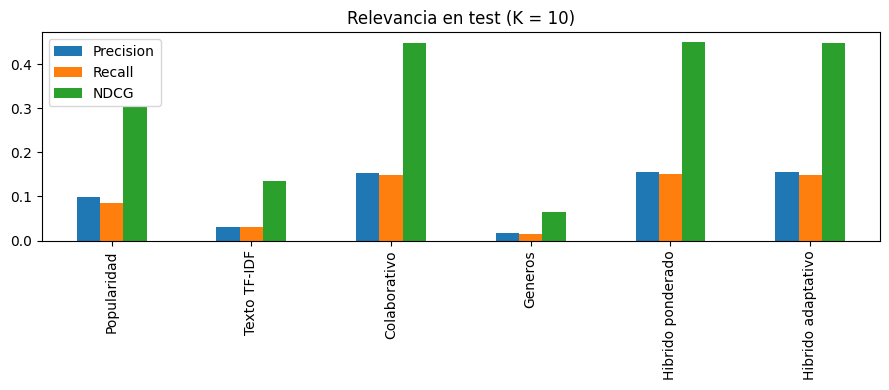

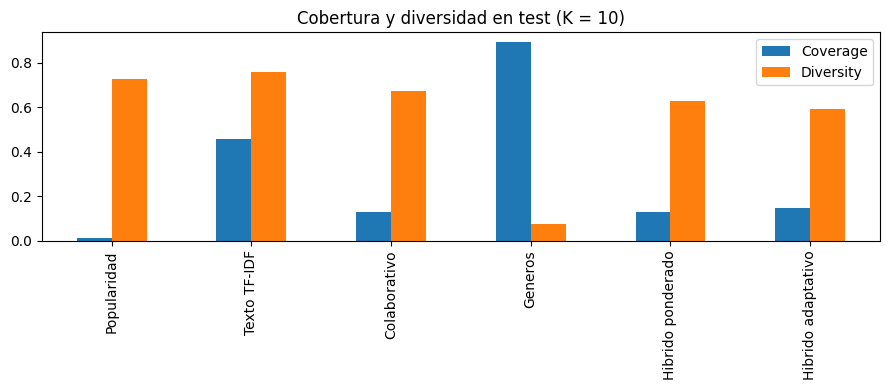

In [23]:
# 22. Comparación consolidada (K = 5 y K = 10 en una sola tabla)
results = pd.concat(resultados, axis=1)
results.columns = [f"{m}@{k}" for k, m in results.columns]
display(results.round(4))

resultados[10][["Precision", "Recall", "NDCG"]].plot(kind="bar", figsize=(9, 4), title="Relevancia en test (K = 10)")
plt.tight_layout(); plt.show()
resultados[10][["Coverage", "Diversity"]].plot(kind="bar", figsize=(9, 4), title="Cobertura y diversidad en test (K = 10)")
plt.tight_layout(); plt.show()


Más preciso: Hibrido ponderado | Más novedoso: Generos


,Precision,Recall,NDCG,Coverage,Diversity,Novelty
Hibrido ponderado,0.1553,0.1497,0.4493,0.1298,0.6270,2.0563
Generos,0.0160,0.0153,0.0654,0.8934,0.0763,6.4296


Hibrido ponderado tiene 9.7 veces la Precision@10 de Generos, pero recomienda solo 504 películas distintas frente a 3469.
Correlación entre Precision@10 y Novelty@10 de los seis modelos: -0.919


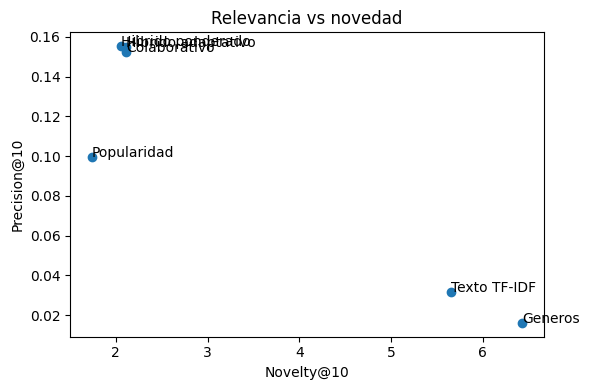

In [24]:
# 23. Caso: mayor relevancia con costo en otra dimensión
r10 = resultados[10]
mas_preciso, mas_novedoso = r10["Precision"].idxmax(), r10["Novelty"].idxmax()
print(f"\nMás preciso: {mas_preciso} | Más novedoso: {mas_novedoso}")
display(r10.loc[[mas_preciso, mas_novedoso]].round(4))
print(f"{mas_preciso} tiene {r10.loc[mas_preciso, 'Precision'] / r10.loc[mas_novedoso, 'Precision']:.1f} veces "
      f"la Precision@10 de {mas_novedoso}, pero recomienda solo "
      f"{r10.loc[mas_preciso, 'Coverage'] * len(movies):.0f} películas distintas frente a "
      f"{r10.loc[mas_novedoso, 'Coverage'] * len(movies):.0f}.")
print("Correlación entre Precision@10 y Novelty@10 de los seis modelos:",
      round(r10["Precision"].corr(r10["Novelty"]), 3))

plt.figure(figsize=(6, 4))
plt.scatter(r10["Novelty"], r10["Precision"])
for nombre in r10.index:
    plt.annotate(nombre, (r10.loc[nombre, "Novelty"], r10.loc[nombre, "Precision"]))
plt.xlabel("Novelty@10"); plt.ylabel("Precision@10"); plt.title("Relevancia vs novedad")
plt.tight_layout(); plt.show()

**Respuesta Pregunta 4**

Evaluación sobre los 5,979 usuarios con al menos una película relevante (rating ≥ 4) en test. Diversidad = 1 − similitud promedio de géneros entre pares de la lista; novedad = promedio de −log2(probabilidad de que un usuario haya visto la película en train); cobertura = películas distintas recomendadas / 3,883. El NDCG sigue la fórmula de clase (el ideal se calcula con los aciertos de la propia lista), por lo que mide solo el orden de los aciertos y da valores más altos que el NDCG estándar.

**Comparación (K = 10).**
- *Mayor Precision@10:* híbrido ponderado (0.1553), seguido del adaptativo (0.1551) y del colaborativo (0.1522). Popularidad 0.0994, texto 0.0314, géneros 0.0160.
- *Mayor Recall@10:* híbrido ponderado (0.1497), casi igual que el adaptativo (0.1489) y el colaborativo (0.1483).
- *Mejor ordenamiento (NDCG@10):* híbrido ponderado (0.4493), adaptativo (0.4484), colaborativo (0.4478).
- *Cobertura:* géneros usa el 89.3% del catálogo y texto el 45.6%; los híbridos entre 13.0% y 14.6%, el colaborativo 12.7% y popularidad solo 1.2%.
- *Diversidad:* texto (0.7594) y popularidad (0.7256) son los más diversos; géneros es el menos diverso (0.0763) porque llena la lista con un solo género.
- *Novedad:* géneros (6.43) y texto (5.65) frente a cerca de 2.1 de colaborativo e híbridos y 1.74 de popularidad.
- En K = 5 el orden se mantiene: híbrido ponderado 0.1858 de Precision@5, adaptativo 0.1856, colaborativo 0.1814.

**Los híbridos frente al colaborativo.** La ganancia en relevancia es muy pequeña (Precision@10 0.1553 frente a 0.1522) y tiene costo: la diversidad baja de 0.6758 a 0.6270 (ponderado) y 0.5904 (adaptativo). El adaptativo es el que más catálogo usa de los tres (14.6%).

**Caso: mayor relevancia con costo en otra dimensión.** El híbrido ponderado tiene 9.7 veces la Precision@10 de géneros (0.1553 frente a 0.0160), pero recomienda solo 504 películas distintas frente a 3,469, y su novedad es 2.06 frente a 6.43. Entre los seis modelos, la correlación entre Precision@10 y Novelty@10 es −0.919: los modelos que más aciertan son los que recomiendan lo más conocido.

**Pruebas automáticas.** Las métricas se verifican con `assert` sobre ejemplos pequeños con resultado conocido (2 aciertos de 5 → precisión 0.4; acierto en la posición 2 → NDCG 1/log2(3); dos películas idénticas → diversidad 0; etc.). Todas pasan.

**Interpretación empresarial**
- Entrada => las listas Top-5 y Top-10 de cada modelo y las películas relevantes de cada usuario en test.
- Datos => ratings ≥ 4 de test, géneros de las películas y frecuencia de cada película en train.
- Modelo => seis recomendadores comparados con seis métricas.
- Salida => tabla consolidada y gráficos de relevancia, cobertura, diversidad y novedad.
- Beneficio esperado => elegir el modelo sabiendo cuánto descubrimiento se pierde por cada punto de relevancia.

**Limitación:** test solo contiene el 15% de los ratings de cada usuario, así que una recomendación buena que el usuario no calificó cuenta como error y las precisiones son bajas en términos absolutos. La relevancia offline tampoco mide si el usuario habría visto la película recomendada.

**PREGUNTA 5: Investiga la robustez del mejor híbrido**


   * Selecciona uno de tus híbridos con base en los resultados de validación y realiza dos experimentos de sensibilidad: uno con menos historial de usuario y otro con una restricción a la concentración de películas populares.

  * Compara los resultados con la configuración original utilizando las seis métricas, presenta diferencias entre grupos de usuarios y concluye qué compromisos revela cada experimento.

In [25]:
# 24. Selección del híbrido con los resultados de validación (NDCG@10 en val)
ndcg_val = {
    "Hibrido ponderado": tabla_ndcg[pesos_h1].mean(),
    "Hibrido adaptativo": np.mean([tabla_ndcg.loc[u, pesos_h2[segmentos_val[u]]] for u in usuarios_val]),
}
hibrido_elegido = max(ndcg_val, key=ndcg_val.get)
print("NDCG@10 en val:", {m: round(float(v), 4) for m, v in ndcg_val.items()})
print("Híbrido elegido:", hibrido_elegido)

def pesos_elegidos(segmento):
    return pesos_h2[segmento] if hibrido_elegido == "Hibrido adaptativo" else pesos_h1

NDCG@10 en val: {'Hibrido ponderado': 0.4544, 'Hibrido adaptativo': 0.4579}
Híbrido elegido: Hibrido adaptativo


In [26]:
# 25. Funciones para los experimentos de sensibilidad
def componentes_historial(userId, gustadas):
    # igual que componentes(), pero con el historial que se le pase
    comp = np.zeros((len(movies), 4))
    comp[:, 0] = pop_base
    if gustadas is not None and len(gustadas) > 0:
        idx, w = posicion[gustadas.index].values, gustadas.values
        comp[:, 1] = w @ S_cf[idx] / w.sum()
        comp[:, 2] = cosine_similarity((w @ matriz_tfidf[idx].toarray()).reshape(1, -1), matriz_tfidf).ravel()
        comp[:, 3] = w @ S_txt[idx] / w.sum()
    candidatos = np.ones(len(movies), dtype=bool)
    candidatos[posicion[list(vistas_train.get(userId, []))].values] = False   # se excluye todo lo visto en train
    comp[candidatos] = MinMaxScaler().fit_transform(comp[candidatos])
    return comp, candidatos

def segmento_por_cantidad(n):
    return "bajo" if n <= corte_bajo else "medio" if n <= corte_alto else "alto"

def puntajes_experimento(userId, fraccion_historial=1.0):
    gustadas = gustos_train.get(userId)
    if gustadas is not None and fraccion_historial < 1:
        n = max(1, int(round(len(gustadas) * fraccion_historial)))
        gustadas = gustadas.sample(n, random_state=userId)        # el modelo solo "conoce" una parte
    comp, candidatos = componentes_historial(userId, gustadas)
    n_historial = 0 if gustadas is None else len(gustadas)
    scores = comp @ np.array(pesos_elegidos(segmento_por_cantidad(n_historial)))
    scores[~candidatos] = -np.inf
    return scores

# películas "populares": el 5% del catálogo con más ratings >= 4 en train
n_cabeza = int(0.05 * len(movies))
es_popular = np.zeros(len(movies), dtype=bool)
es_popular[posicion[popularidad.index[:n_cabeza]].values] = True
print("Películas consideradas populares:", n_cabeza)

def lista_top(scores, k, tope_populares=None):
    # tope_populares = fracción máxima de la lista que puede venir de las populares
    max_populares = k if tope_populares is None else int(np.ceil(tope_populares * k))
    lista, n_pop = [], 0
    for i in np.argsort(-scores, kind="stable"):
        if es_popular[i]:
            if n_pop >= max_populares:
                continue
            n_pop += 1
        lista.append(ids[i])
        if len(lista) == k:
            break
    return lista

Películas consideradas populares: 194


In [27]:
# 26. Listas Top-5 y Top-10 de las tres configuraciones (usuarios de test)
FRACCION_HISTORIAL, TOPE_POPULARES = 0.3, 0.3            # fijados de antemano, no ajustados con test
CONFIGS = ["Original", "Menos historial (30%)", "Tope de populares (30%)"]
listas_exp = {c: {5: {}, 10: {}} for c in CONFIGS}

for u in relevantes_test:
    s_original = puntajes_experimento(u)
    s_reducido = puntajes_experimento(u, FRACCION_HISTORIAL)
    for k in [5, 10]:
        listas_exp["Original"][k][u] = lista_top(s_original, k)
        listas_exp["Menos historial (30%)"][k][u] = lista_top(s_reducido, k)
        listas_exp["Tope de populares (30%)"][k][u] = lista_top(s_original, k, TOPE_POPULARES)

# prueba automática: la configuración original reproduce el híbrido de la Pregunta 4
assert all(listas_exp["Original"][10][u] == recomendaciones[hibrido_elegido][u] for u in relevantes_test)
print("Prueba automática: la configuración original coincide con la Pregunta 4.")

Prueba automática: la configuración original coincide con la Pregunta 4.


In [28]:
# 27. Comparación con las seis métricas (K = 5 y K = 10)
def evaluar_listas(listas, k, usuarios):
    p, r, n, d, nov, pct, todas = [], [], [], [], [], [], []
    for u in usuarios:
        rec, relevantes = listas[u], relevantes_test[u]
        p.append(precision_at_k(rec, relevantes, k))
        r.append(recall_at_k(rec, relevantes, k))
        n.append(ndcg_at_k(rec, relevantes, k))
        d.append(diversidad_intralista(rec))
        nov.append(novedad(rec))
        pct.append(es_popular[posicion[rec].values].mean())
        todas.append(rec)
    return {"Precision": np.mean(p), "Recall": np.mean(r), "NDCG": np.mean(n),
            "Coverage": cobertura(todas, len(movies)), "Diversity": np.mean(d),
            "Novelty": np.mean(nov), "Pct_populares": np.mean(pct)}

usuarios_test = list(relevantes_test)
resultados_exp = {}
for k in [5, 10]:
    resultados_exp[k] = pd.DataFrame({c: evaluar_listas(listas_exp[c][k], k, usuarios_test) for c in CONFIGS}).T
    print(f"\nExperimentos en test, K = {k}")
    display(resultados_exp[k].round(4))

print("\nCambio frente a la configuración original (K = 10):")
display((resultados_exp[10] - resultados_exp[10].loc["Original"]).drop("Original").round(4))


Experimentos en test, K = 5


,Precision,Recall,NDCG,Coverage,Diversity,Novelty,Pct_populares
Original,0.1856,0.0937,0.4115,0.1017,0.5561,1.9945,0.9653
Menos historial (30%),0.1728,0.0815,0.3864,0.1733,0.4945,2.1452,0.9296
Tope de populares (30%),0.1406,0.0698,0.3723,0.1460,0.4532,2.6983,0.3977



Experimentos en test, K = 10


,Precision,Recall,NDCG,Coverage,Diversity,Novelty,Pct_populares
Original,0.1551,0.1489,0.4484,0.1463,0.5904,2.1083,0.9480
Menos historial (30%),0.1463,0.1327,0.4205,0.2390,0.5284,2.2595,0.9076
Tope de populares (30%),0.1141,0.1076,0.4173,0.1960,0.4623,2.8725,0.2990



Cambio frente a la configuración original (K = 10):


,Precision,Recall,NDCG,Coverage,Diversity,Novelty,Pct_populares
Menos historial (30%),-0.0088,-0.0162,-0.0279,0.0927,-0.0620,0.1513,-0.0404
Tope de populares (30%),-0.0410,-0.0413,-0.0311,0.0497,-0.1281,0.7643,-0.6489


In [29]:
# 28. Diferencias entre grupos de usuarios (por tamaño de historial en train, K = 10)
grupo_test = pd.Series({u: segmento_historial(u) for u in usuarios_test})
print("Usuarios por grupo:", grupo_test.value_counts().to_dict())

filas = {}
for c in CONFIGS:
    for g in ["bajo", "medio", "alto"]:
        filas[(c, g)] = evaluar_listas(listas_exp[c][10], 10, grupo_test.index[grupo_test == g])
por_grupo = pd.DataFrame(filas).T
display(por_grupo.round(4))

precision_grupo = por_grupo["Precision"].unstack()[["bajo", "medio", "alto"]].loc[CONFIGS]
novedad_grupo = por_grupo["Novelty"].unstack()[["bajo", "medio", "alto"]].loc[CONFIGS]
print("Cambio relativo de Precision@10 frente al original, por grupo (%):")
display(((precision_grupo / precision_grupo.loc["Original"] - 1) * 100).drop("Original").round(1))
print("Cambio de Novelty@10 frente al original, por grupo:")
display((novedad_grupo - novedad_grupo.loc["Original"]).drop("Original").round(3))

Usuarios por grupo: {'medio': 2009, 'bajo': 1985, 'alto': 1985}


Precision  Recall    NDCG  Coverage  Diversity  \
Original                bajo      0.0601  0.1882  0.2664    0.1352     0.4937   
                        medio     0.1460  0.1622  0.4671    0.0901     0.6072   
                        alto      0.2594  0.0962  0.6115    0.0659     0.6702   
Menos historial (30%)   bajo      0.0505  0.1538  0.2202    0.2233     0.4557   
                        medio     0.1369  0.1512  0.4411    0.1362     0.4905   
                        alto      0.2516  0.0930  0.6000    0.0881     0.6393   
Tope de populares (30%) bajo      0.0440  0.1365  0.2337    0.1839     0.3602   
                        medio     0.1027  0.1152  0.4312    0.1313     0.4795   
                        alto      0.1957  0.0709  0.5868    0.1012     0.5470   

                               Novelty  Pct_populares  
Original                bajo    2.2034         0.9232  
                        medio   2.0608         0.9527  
                        alto    2.0612         0.9680  
Menos historial (30%)   bajo    2.3888         0.8616  
                        medio   2.2731         0.9043  
                        alto    2.1165         0.9569  
Tope de populares (30%) bajo    2.9446         0.2982  
                        medio   2.8442         0.2991  
                        alto    2.8291         0.2998

Cambio relativo de Precision@10 frente al original, por grupo (%):


,bajo,medio,alto
Menos historial (30%),-15.9,-6.2,-3.0
Tope de populares (30%),-26.7,-29.7,-24.6


Cambio de Novelty@10 frente al original, por grupo:


,bajo,medio,alto
Menos historial (30%),0.185,0.212,0.055
Tope de populares (30%),0.741,0.783,0.768


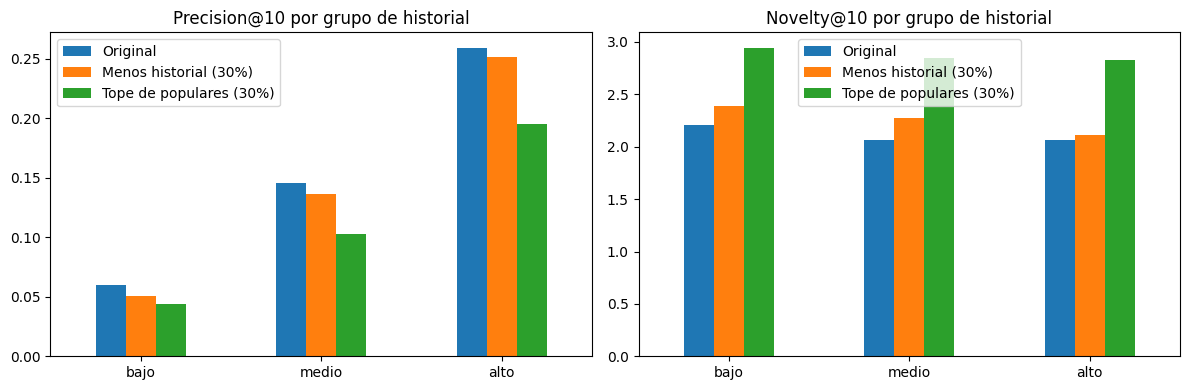

In [30]:
# 29. Gráficos de los experimentos
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
precision_grupo.T.plot(kind="bar", ax=ejes[0], title="Precision@10 por grupo de historial", rot=0)
novedad_grupo.T.plot(kind="bar", ax=ejes[1], title="Novelty@10 por grupo de historial", rot=0)
plt.tight_layout(); plt.show()

**Respuesta Pregunta 5**

**Híbrido seleccionado.** El adaptativo, por tener mayor NDCG@10 en val (0.4579 frente a 0.4544 del ponderado). La elección se hace solo con val; en test ambos quedaron prácticamente empatados.

**Experimentos.** Los parámetros se fijaron de antemano (no se ajustaron con test) y el modelo no se reentrena: solo cambia lo que conoce del usuario o la regla de la lista.
- *Menos historial:* el modelo solo conoce el 30% de las películas que le gustaron a cada usuario (muestra con semilla fija). El segmento del usuario se recalcula con ese historial reducido, y se siguen excluyendo todas las películas vistas en train.
- *Tope de populares:* como máximo el 30% de la lista puede venir de las 194 películas más populares (5% del catálogo): 3 de 10 y 2 de 5.

**Comparación con la configuración original (K = 10, test).**

| Configuración | Precision | Recall | NDCG | Coverage | Diversity | Novelty | % populares |
|---|---|---|---|---|---|---|---|
| Original | 0.1551 | 0.1489 | 0.4484 | 0.1463 | 0.5904 | 2.1083 | 94.8% |
| Menos historial (30%) | 0.1463 | 0.1327 | 0.4205 | 0.2390 | 0.5284 | 2.2595 | 90.8% |
| Tope de populares (30%) | 0.1141 | 0.1076 | 0.4173 | 0.1960 | 0.4623 | 2.8725 | 29.9% |

En K = 5 el patrón es el mismo: Precision@5 pasa de 0.1856 a 0.1728 (menos historial) y a 0.1406 (tope).

**Diferencias entre grupos de usuarios** (por historial en train: 1,985 bajo, 2,009 medio, 1,985 alto).
- *Menos historial:* la Precision@10 cae 15.9% en el grupo bajo (0.0601 → 0.0505), 6.2% en el medio y solo 3.0% en el alto (0.2594 → 0.2516). Quien tenía poco historial queda con casi nada; quien tenía mucho conserva suficiente señal.
- *Tope de populares:* la caída es fuerte y parecida en todos los grupos: 26.7% en bajo, 29.7% en medio y 24.6% en alto. A cambio la novedad sube entre 0.74 y 0.78 en los tres.

**Compromisos que revela cada experimento.**
- *Menos historial:* el híbrido es robusto en relevancia (Precision@10 baja solo 0.0088 en promedio), pero el costo se concentra en los usuarios con poco historial. Con menos historial las listas se vuelven más distintas entre usuarios (cobertura de 14.6% a 23.9%) pero más parecidas por dentro (diversidad de 0.5904 a 0.5284): el perfil queda definido por pocas películas.
- *Tope de populares:* el híbrido original depende casi por completo de los éxitos (94.8% de sus recomendaciones vienen del 5% más popular del catálogo). Limitar esa concentración sube la novedad de 2.11 a 2.87 y la cobertura de 14.6% a 19.6%, pero cuesta el 26.4% de la Precision@10 (0.1551 → 0.1141) y baja la diversidad a 0.4623. Es una palanca directa de descubrimiento con un costo claro en relevancia.

**Interpretación empresarial**
- Entrada => el híbrido adaptativo, los usuarios de test y dos cambios controlados (historial al 30%, tope de populares al 30%).
- Datos => historial de train, popularidad de las películas en train y películas relevantes de test.
- Modelo => el mismo híbrido, sin reentrenar, bajo tres configuraciones.
- Salida => las seis métricas por configuración y por grupo de historial.
- Beneficio esperado => saber cuánto se degrada el servicio para usuarios nuevos y cuánta relevancia cuesta forzar el descubrimiento.

**Limitación:** se probó un solo valor de cada parámetro (30%), así que no se conoce la curva completa del compromiso. El experimento de menos historial reduce solo el perfil del usuario; las similitudes entre películas siguen calculadas con todo train, por lo que no equivale a una plataforma con pocos datos.


**PREGUNTA 6: Decide y defiende una solución de negocio**


  * Para una plataforma que busca aumentar el descubrimiento de películas poco populares sin sacrificar excesivamente la relevancia, recomienda un único modelo para un piloto.
   
   * Sustenta tu elección con una matriz de decisión ponderada, dos riesgos técnicos, una limitación de los datos y una condición observable que te haría reconsiderar la elección.
   
   * Prepara una defensa, ejecutando tu notebook para mostrar una recomendación concreta, una prueba automática y un resultado experimental inesperado.

In [31]:
# 30. Candidatos para el piloto y sus métricas en test (K = 10)
NOMBRE_TOPE = "Hibrido adaptativo + tope"
candidatos_piloto = {nombre: recomendaciones[nombre] for nombre in modelos}
candidatos_piloto[NOMBRE_TOPE] = listas_exp["Tope de populares (30%)"][10]

metricas = pd.DataFrame({c: evaluar_listas(listas, 10, usuarios_test)
                         for c, listas in candidatos_piloto.items()}).T
metricas["Cola_larga"] = 1 - metricas["Pct_populares"]      # % de recomendaciones fuera de las populares
display(metricas.round(4))

,Precision,Recall,NDCG,Coverage,Diversity,Novelty,Pct_populares,Cola_larga
Popularidad,0.0994,0.0845,0.3028,0.0124,0.7256,1.7364,1.0000,0.0000
Texto TF-IDF,0.0314,0.0298,0.1342,0.4558,0.7594,5.6523,0.1258,0.8742
Colaborativo,0.1522,0.1483,0.4478,0.1267,0.6758,2.1094,0.9566,0.0434
Generos,0.0160,0.0153,0.0654,0.8934,0.0763,6.4296,0.0716,0.9284
Hibrido ponderado,0.1553,0.1497,0.4493,0.1298,0.6270,2.0563,0.9569,0.0431
Hibrido adaptativo,0.1551,0.1489,0.4484,0.1463,0.5904,2.1083,0.9480,0.0520
Hibrido adaptativo + tope,0.1141,0.1076,0.4173,0.1960,0.4623,2.8725,0.2990,0.7010


In [32]:
# 31. Matriz de decisión ponderada
pesos_decision = {"Precision": 0.30, "NDCG": 0.10,                          # relevancia: 40%
                  "Cola_larga": 0.20, "Novelty": 0.15, "Coverage": 0.10,    # descubrimiento: 45%
                  "Diversity": 0.15}                                        # diversidad: 15%
RETENCION_MINIMA = 0.70      # "sin sacrificar excesivamente": conservar 70% de la mejor Precision@10

def matriz_decision(pesos):
    criterios = list(pesos)
    normalizada = metricas[criterios] / metricas[criterios].max()           # cada criterio de 0 a 1
    matriz = normalizada * pd.Series(pesos)
    matriz["Puntaje"] = matriz.sum(axis=1)
    matriz["Retencion_precision"] = metricas["Precision"] / metricas["Precision"].max()
    matriz["Cumple_relevancia"] = matriz["Retencion_precision"] >= RETENCION_MINIMA
    return matriz.sort_values("Puntaje", ascending=False)

matriz = matriz_decision(pesos_decision)
display(matriz.round(3))
modelo_piloto = matriz[matriz["Cumple_relevancia"]]["Puntaje"].idxmax()
print("Modelo recomendado para el piloto:", modelo_piloto)

,Precision,NDCG,Cola_larga,Novelty,Coverage,Diversity,Puntaje,Retencion_precision,Cumple_relevancia
Hibrido adaptativo + tope,0.220,0.093,0.151,0.067,0.022,0.091,0.645,0.735,True
Texto TF-IDF,0.061,0.030,0.188,0.132,0.051,0.150,0.612,0.202,False
Colaborativo,0.294,0.100,0.009,0.049,0.014,0.133,0.600,0.980,True
Hibrido ponderado,0.300,0.100,0.009,0.048,0.015,0.124,0.596,1.000,True
Hibrido adaptativo,0.300,0.100,0.011,0.049,0.016,0.117,0.593,0.999,True
Generos,0.031,0.015,0.200,0.150,0.100,0.015,0.511,0.103,False
Popularidad,0.192,0.067,0.000,0.041,0.001,0.143,0.445,0.640,False


Modelo recomendado para el piloto: Hibrido adaptativo + tope


In [33]:
# 32. Sensibilidad de la decisión a los pesos
escenarios = {
    "Base (descubrimiento 45%)": pesos_decision,
    "Más relevancia (60%)": {"Precision": 0.45, "NDCG": 0.15, "Cola_larga": 0.10,
                             "Novelty": 0.10, "Coverage": 0.05, "Diversity": 0.15},
    "Más descubrimiento (60%)": {"Precision": 0.20, "NDCG": 0.05, "Cola_larga": 0.30,
                                 "Novelty": 0.20, "Coverage": 0.10, "Diversity": 0.15},
}
filas = {}
for nombre, pesos in escenarios.items():
    m = matriz_decision(pesos)
    validos = m[m["Cumple_relevancia"]]["Puntaje"]
    filas[nombre] = {"Ganador con requisito": validos.idxmax(), "Puntaje": round(validos.max(), 3),
                     "Segundo": validos.index[1], "Puntaje segundo": round(validos.iloc[1], 3),
                     "Ganador sin requisito": m["Puntaje"].idxmax()}
display(pd.DataFrame(filas).T)

,Ganador con requisito,Puntaje,Segundo,Puntaje segundo,Ganador sin requisito
Base (descubrimiento 45%),Hibrido adaptativo + tope,0.645,Colaborativo,0.6,Hibrido adaptativo + tope
Más relevancia (60%),Colaborativo,0.768,Hibrido ponderado,0.768,Colaborativo
Más descubrimiento (60%),Hibrido adaptativo + tope,0.622,Colaborativo,0.473,Texto TF-IDF


In [34]:
# 33. Defensa (1): una recomendación concreta
u = usuarios_demo[0]
scores_u = puntajes_experimento(u)
sin_tope, con_tope = lista_top(scores_u, 10), lista_top(scores_u, 10, TOPE_POPULARES)
print(f"Usuario {u} | géneros que más le gustaron:",
      generos.loc[gustos_train[u].index].str.split("|").explode().value_counts().head(3).to_dict())
display(pd.DataFrame({
    "Hibrido adaptativo": titulos.loc[sin_tope].values,
    "popular": es_popular[posicion[sin_tope].values],
    "Hibrido adaptativo + tope": titulos.loc[con_tope].values,
    "popular ": es_popular[posicion[con_tope].values],
    "ratings >= 4 en train": popularidad.loc[con_tope].values,
}, index=range(1, 11)))

Usuario 1 | géneros que más le gustaron: {'Drama': 15, "Children's": 12, 'Animation': 11}


,Hibrido adaptativo,popular,Hibrido adaptativo + tope,popular,ratings >= 4 en train
1,Toy Story (1995),True,Toy Story (1995),True,1175
2,"Shawshank Redemption, The (1994)",True,"Shawshank Redemption, The (1994)",True,1479
3,American Beauty (1999),True,American Beauty (1999),True,1969
4,E.T. the Extra-Terrestrial (1982),True,Fantasia (1940),False,445
5,Star Wars: Episode V - The Empire Strikes Back...,True,Lady and the Tramp (1955),False,413
6,"Lion King, The (1994)",True,It's a Wonderful Life (1946),False,413
7,"Silence of the Lambs, The (1991)",True,Sleeping Beauty (1959),False,216
8,Star Wars: Episode IV - A New Hope (1977),True,"Jungle Book, The (1967)",False,305
9,Fantasia (1940),False,Field of Dreams (1989),False,383
10,Raiders of the Lost Ark (1981),True,Back to the Future Part II (1989),False,370


In [35]:
# 34. Defensa (2): prueba automática del modelo elegido
for usuario, lista in candidatos_piloto[NOMBRE_TOPE].items():
    assert len(lista) == 10 and len(set(lista)) == 10                       # 10 películas distintas
    assert not set(lista) & vistas_train[usuario]                           # ninguna vista en train
    assert es_popular[posicion[lista].values].sum() <= 3                    # máximo 3 populares
print(f"Prueba automática superada para {len(candidatos_piloto[NOMBRE_TOPE])} usuarios: "
      "10 películas distintas, ninguna vista en train y como máximo 3 populares por lista.")

Prueba automática superada para 5979 usuarios: 10 películas distintas, ninguna vista en train y como máximo 3 populares por lista.


In [36]:
# 35. Defensa (3): un resultado experimental inesperado
original, tope = metricas.loc["Hibrido adaptativo"], metricas.loc[NOMBRE_TOPE]
print("Al limitar las películas populares:")
print(f"  Novelty@10   sube de {original['Novelty']:.4f} a {tope['Novelty']:.4f}")
print(f"  Coverage@10  sube de {original['Coverage']:.4f} a {tope['Coverage']:.4f}")
print(f"  Diversity@10 BAJA de {original['Diversity']:.4f} a {tope['Diversity']:.4f}")
cola = ~es_popular
print("Géneros distintos entre las 194 populares:", generos[es_popular].str.split("|").explode().nunique(),
      "| entre el resto:", generos[cola].str.split("|").explode().nunique())
print("Similitud de géneros promedio dentro de las listas (1 - Diversity):",
      f"original {1 - original['Diversity']:.4f} | con tope {1 - tope['Diversity']:.4f}")

Al limitar las películas populares:
  Novelty@10   sube de 2.1083 a 2.8725
  Coverage@10  sube de 0.1463 a 0.1960
  Diversity@10 BAJA de 0.5904 a 0.4623
Géneros distintos entre las 194 populares: 17 | entre el resto: 18
Similitud de géneros promedio dentro de las listas (1 - Diversity): original 0.4096 | con tope 0.5377


**Respuesta Pregunta 6**

**Modelo recomendado para el piloto: híbrido adaptativo con tope de populares** (como máximo el 30% de cada lista puede venir de las 194 películas más populares).

**Matriz de decisión ponderada** (K = 10 en test; cada criterio se divide entre el mejor valor de los siete candidatos y se multiplica por su peso). Pesos según el objetivo del negocio: relevancia 40% (Precision 30%, NDCG 10%), descubrimiento 45% (cola larga 20%, novedad 15%, cobertura 10%) y diversidad 15%. "Cola larga" es el porcentaje de recomendaciones fuera de las populares. Requisito mínimo de relevancia: conservar al menos el 70% de la mejor Precision@10.

| Candidato | Puntaje | Retención de precisión | Cumple requisito |
|---|---|---|---|
| Híbrido adaptativo + tope | 0.645 | 73.5% | Sí |
| Texto TF-IDF | 0.612 | 20.2% | No |
| Colaborativo | 0.600 | 98.0% | Sí |
| Híbrido ponderado | 0.596 | 100.0% | Sí |
| Híbrido adaptativo | 0.593 | 99.9% | Sí |
| Géneros | 0.511 | 10.3% | No |
| Popularidad | 0.445 | 64.0% | No |

**Por qué este modelo.** Es el único candidato que mueve de verdad el descubrimiento sin perder la relevancia: el 70.1% de sus recomendaciones son de cola larga (frente al 5.2% del híbrido adaptativo original y el 4.3% del colaborativo), su novedad sube de 2.11 a 2.87 y conserva el 73.5% de la mejor Precision@10 (0.1141 frente a 0.1553). Texto y géneros descubren más, pero conservan solo el 20.2% y el 10.3% de la precisión: eso sí es sacrificar excesivamente la relevancia.

**Sensibilidad de la decisión a los pesos.** Con más peso al descubrimiento (60%) gana el mismo modelo (0.622 frente a 0.473 del colaborativo). Con más peso a la relevancia (60%) gana el colaborativo, empatado con el híbrido ponderado (0.768). La elección depende de que el negocio priorice el descubrimiento, que es lo que plantea el caso.

**Dos riesgos técnicos.**
1. *Dependencia del colaborativo en la cola larga.* El componente con más peso (0.6 a 0.7) calcula similitudes con los ratings de train; las películas poco vistas tienen pocos ratings, así que su similitud es ruidosa, y 222 películas del catálogo no tienen ningún rating en train y solo pueden entrar por géneros o texto.
2. *El tope es una regla fija aplicada después del ranking.* La lista de "populares" se calculó una vez con train y envejece cuando cambian los gustos; además reemplaza películas con mejor puntaje por otras peores y baja la diversidad de géneros (0.5904 → 0.4623). Los pesos por segmento también son frágiles: se eligieron con 1,000 usuarios de val y diferencias pequeñas (NDCG@10 0.3073 frente a 0.2966).

**Una limitación de los datos.** MovieLens registra calificaciones, no reproducciones: una película recomendada que el usuario habría visto con gusto pero no calificó cuenta como error, y test solo tiene el 15% de los ratings de cada usuario. Además todos los usuarios tienen al menos 20 calificaciones y los datos son de alrededor del año 2000, así que no representan usuarios nuevos ni el consumo actual.

**Condición observable que me haría reconsiderar.** Si en el piloto la tasa de reproducción de las recomendaciones cae más de 26% frente al grupo de control con el híbrido sin tope (26.4% es la caída de Precision@10 medida offline), o si las películas de cola larga recomendadas no reciben reproducciones, volvería al híbrido adaptativo sin tope o subiría el tope por encima del 30%.

**Defensa (se ejecuta en las celdas 33 a 35).**
- *Recomendación concreta:* al usuario 1 (le gustan Drama, Children's y Animation) el híbrido original le da 9 éxitos entre 10 (*Star Wars*, *Raiders of the Lost Ark*, *Silence of the Lambs*). Con el tope conserva *Toy Story*, *Shawshank Redemption* y *American Beauty*, y el resto pasa a ser *Lady and the Tramp*, *Sleeping Beauty*, *Jungle Book* y *Fantasia*: menos populares (216 a 445 ratings positivos en train) y afines a su gusto por la animación infantil.
- *Prueba automática:* para los 5,979 usuarios de test se verifica con `assert` que cada lista tiene 10 películas distintas, ninguna vista en train y como máximo 3 populares.
- *Resultado inesperado:* limitar las películas populares sube la novedad (2.1083 → 2.8725) y la cobertura (0.1463 → 0.1960), pero **baja** la diversidad dentro de la lista (0.5904 → 0.4623). Se esperaba lo contrario. Al quitar los éxitos, que son de géneros variados, la lista se llena con las películas de cola larga más parecidas al perfil del usuario, que comparten géneros entre sí.

**Interpretación empresarial**
- Entrada => las métricas en test de siete candidatos y las prioridades del negocio.
- Datos => Precision, NDCG, cola larga, novedad, cobertura y diversidad a K = 10.
- Modelo => matriz de decisión ponderada con un requisito mínimo de relevancia.
- Salida => un único modelo para el piloto: híbrido adaptativo con tope de populares.
- Beneficio esperado => llevar al usuario hacia el catálogo poco visto (70.1% de recomendaciones de cola larga) conservando cerca de tres cuartos de la relevancia.

**Limitación:** los pesos de la matriz y el requisito del 70% son decisiones de negocio supuestas; con otras prioridades gana el colaborativo. El piloto con usuarios reales es el que debe confirmar la elección.